# Exercice 6 : Apprentissage fédéré, entraîner entre hôpitaux sans partager les dossiers

> **Objectif.** Entraîner un modèle commun à 14 hôpitaux **sans qu'aucun dossier ne quitte son hôpital** (FedAvg), puis montrer que ce qui circule à la place, les **gradients**, peut redonner les dossiers.
> Enfin, mesurer deux défenses : l'**agrégation sécurisée** et **DP-SGD** dans chaque hôpital.

**Volets du plan de cours (séance 12) :** *apprentissage décentralisé* et *prévention des fuites d'information* (avec un retour sur les *mécanismes formels de confidentialité* de l'exercice 5).

**Le scénario.** Les hôpitaux du Massachusetts veulent un modèle de risque de **prédiabète**. Mettre tous les dossiers dans une même base centrale pose problème : il faut une base légale pour chaque transfert (Loi 25, HIPAA), et une seule fuite expose tout le monde.
L'**apprentissage fédéré** (McMahan *et al.*, AISTATS 2017) inverse la logique : **le modèle voyage, les données restent**.

**Ce n'est pas théorique.**
- **Google Gboard** entraîne la prédiction du prochain mot sur les téléphones, sans envoyer ce que les gens tapent (Hard *et al.*, 2018).
- **FeTS** : 71 hôpitaux sur 6 continents ont entraîné ensemble un modèle de segmentation de tumeurs cérébrales sans échanger une seule IRM (Pati *et al.*, *Nature Communications*, 2022).

**Dépendances :** `torch`, `opacus`, `scikit-learn`, `matplotlib` (installés par l'étape 0).

**Les données.** Les 10 262 patients adultes de **Synthea « 10K COVID-19 »** (Apache 2.0, synthétiques), ceux des exercices 3 à 5. Chaque patient est rattaché à son **comté de résidence** : on en fait 14 hôpitaux, de 27 patients (Nantucket) à 1 854 (Middlesex).

**Le plan.**
1. Les 14 hôpitaux.
2. Chacun seul, ou tout centralisé.
3. FedAvg, écrit à la main.
4. Ce qui circule : un gradient d'un seul patient redonne son dossier.
5. « On envoie des lots » : un serveur malveillant les vide quand même.
6. Défense 1 : l'agrégation sécurisée.
7. Défense 2 : DP-SGD dans chaque hôpital.

## Étape 0 : exécutez cette cellule en premier
Elle installe les paquets manquants et, sur Colab, récupère `helper.py` et `data/` depuis GitHub. Elle doit afficher **Prêt : True**.

In [1]:
# Dépendances de ce notebook : torch opacus scikit-learn matplotlib
import os, sys, importlib.util
if not os.path.exists('helper.py'):   # notebook ouvert depuis Google Drive / Colab
    !test -d /content/cours || git clone -q --depth 1 https://github.com/elyesmanai/8IAR805---Cybersecurity-AI.git /content/cours
    %cd "/content/cours/Chapitre 7 - IA et vie privée"
manquants = [pip for module, pip in {'torch': 'torch', 'opacus': 'opacus', 'sklearn': 'scikit-learn', 'matplotlib': 'matplotlib'}.items() if importlib.util.find_spec(module) is None]
if manquants:
    %pip install -q {' '.join(manquants)}
print('Prêt :', os.path.exists('helper.py') and os.path.exists('data'))

Prêt : True


## Étape 1 : Les 14 hôpitaux
**Ce qu'on fait :** on répartit les patients par comté. 20 % des patients (tirés dans tous les comtés) forment un **jeu de test commun**, qui sert seulement à mesurer les modèles.

In [2]:
import numpy as np, pandas as pd, torch
torch.set_num_threads(4)
from helper import hopitaux

X, y, colonnes, test, hop = hopitaux()
pd.DataFrame({'patients': {h: len(ix) for h, ix in hop.items()},
              'prédiabète': {h: y[ix].mean().round(2) for h, ix in hop.items()}}).T

,Middlesex,Worcester,Suffolk,Norfolk,Essex,Bristol,Plymouth,Hampden,Barnstable,Berkshire,Hampshire,Franklin,Dukes,Nantucket
patients,1854.00,1044.00,918.00,890.0,872.0,671.00,562.00,550.00,316.00,196.00,186.00,82.00,42.0,27.00
prédiabète,0.36,0.37,0.35,0.4,0.4,0.38,0.39,0.38,0.48,0.44,0.35,0.45,0.4,0.33


**👀 Ce qu'on doit voir :** des hôpitaux très inégaux. Middlesex a 1 854 patients, Dukes 42, Nantucket 27. Un petit hôpital n'a pas assez de dossiers pour entraîner un bon modèle seul.

## Étape 2 : Chacun seul, ou tout centralisé
**Ce qu'on fait :** deux références.
- **Chacun seul** : chaque hôpital entraîne son modèle sur ses seuls patients (aucun partage, mais peu de données).
- **Tout centralisé** : on réunit les 8 210 dossiers d'entraînement dans une seule base (le meilleur modèle possible, mais tous les dossiers sortent des hôpitaux).

Même réseau qu'aux exercices 4 et 5, régularisé (*dropout* 30 %, *weight decay*), 20 époques. Environ 20 secondes.

In [3]:
from helper import creer_mlp, entrainer, precision_test

seul = {h: precision_test(entrainer(creer_mlp(X.shape[1], dropout=0.3), X[ix], y[ix], epoques=20, weight_decay=1e-2), X[test], y[test])
        for h, ix in hop.items()}
tous = np.concatenate(list(hop.values()))
central = precision_test(entrainer(creer_mlp(X.shape[1], dropout=0.3), X[tous], y[tous], epoques=20, weight_decay=1e-2), X[test], y[test])
print(f'Tout centralisé : précision test = {central:.3f}')
pd.Series(seul, name='précision test, hôpital seul').round(3).to_frame().T

Tout centralisé : précision test = 0.882


,Middlesex,Worcester,Suffolk,Norfolk,Essex,Bristol,Plymouth,Hampden,Barnstable,Berkshire,Hampshire,Franklin,Dukes,Nantucket
"précision test, hôpital seul",0.88,0.872,0.851,0.872,0.874,0.866,0.874,0.869,0.854,0.837,0.844,0.839,0.762,0.711


**👀 Ce qu'on doit voir :** le modèle centralisé atteint ≈ 0,88. Les gros hôpitaux seuls s'en approchent (≈ 0,87-0,88), mais **Dukes (≈ 0,76) et Nantucket (≈ 0,71)** font à peine mieux que « toujours répondre non » (≈ 0,62).
Les petits hôpitaux, souvent ruraux, sont ceux qui ont le plus besoin de collaborer.

## Étape 3 : FedAvg, écrit à la main
**L'algorithme (McMahan *et al.*, 2017)**, à chaque **ronde** :
1. le serveur envoie les poids du modèle global à chaque hôpital ;
2. chaque hôpital entraîne **une époque** sur ses propres dossiers ;
3. chaque hôpital renvoie ses **poids** (jamais ses données) ;
4. le serveur fait la **moyenne des poids**, pondérée par le nombre de patients de chaque hôpital.

**Ce qu'on fait :** 20 rondes. Environ 10 secondes.

In [4]:
from helper import poids, charger_poids, entrainement_local

def moyenne_ponderee(liste_poids, tailles):
    t = np.array(tailles) / sum(tailles)
    return [sum(ti * w[i] for ti, w in zip(t, liste_poids)) for i in range(len(liste_poids[0]))]

modele_global = creer_mlp(X.shape[1], dropout=0.3)
historique = []
for ronde in range(1, 21):
    w_global = poids(modele_global)                                                       # 1. le serveur envoie
    recus = [entrainement_local(w_global, X[ix], y[ix], graine=ronde) for ix in hop.values()]   # 2-3. chaque hôpital entraîne et renvoie
    charger_poids(modele_global, moyenne_ponderee(recus, [len(ix) for ix in hop.values()]))    # 4. moyenne pondérée
    historique.append(precision_test(modele_global, X[test], y[test]))

federe = historique[-1]
print(f'Fédéré (20 rondes) : {federe:.3f} | centralisé : {central:.3f} | Nantucket seul : {seul["Nantucket"]:.3f}')

Fédéré (20 rondes) : 0.876 | centralisé : 0.882 | Nantucket seul : 0.711


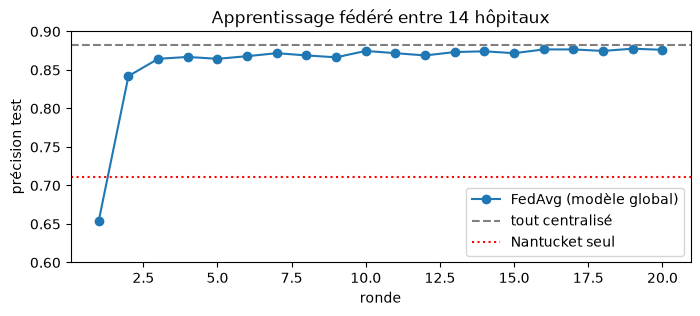

In [5]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 3))
plt.plot(range(1, 21), historique, 'o-', label='FedAvg (modèle global)')
plt.axhline(central, color='gray', ls='--', label='tout centralisé')
plt.axhline(seul['Nantucket'], color='red', ls=':', label='Nantucket seul')
plt.xlabel('ronde'); plt.ylabel('précision test'); plt.ylim(0.6, 0.9); plt.legend(); plt.title('Apprentissage fédéré entre 14 hôpitaux');

**👀 Ce qu'on doit voir :** dès la 4e ronde, le modèle fédéré dépasse 0,86 ; après 20 rondes, il est à **moins d'un point** du modèle centralisé (≈ 0,88). Nantucket passe de ≈ 0,71 à ≈ 0,88 **sans avoir envoyé un seul dossier**.

**❓ Question pour la classe :** les dossiers ne sortent pas. Les données sont-elles pour autant protégées ? Qu'est-ce qui sort, exactement ?

## Étape 4 : Ce qui circule, c'est un gradient… et il redonne le dossier
**Ce qu'on fait :** dans la variante la plus simple (**FedSGD**), un hôpital envoie le **gradient** calculé sur ses patients. Prenons le cas extrême : un gradient calculé sur **un seul** patient de Nantucket.

**Pourquoi ça fuit (Phong *et al.*, 2018) :** la première couche calcule `h = W·x + b`. Pour chaque neurone *k*, le gradient vaut `dW[k] = δ_k · x` et `db[k] = δ_k`. Donc **`dW[k] / db[k] = x`** : le dossier, exactement, en une division.

In [6]:
from helper import gradient_lot

modele = creer_mlp(X.shape[1]).eval()               # un modèle quelconque, ici celui du début de l'entraînement
patient = hop['Nantucket'][0]
dW, db = gradient_lot(modele, X[[patient]], y[[patient]])     # ce que l'hôpital envoie au serveur

k = db.abs().argmax()                                # n'importe quel neurone actif
reconstruit = (dW[k] / db[k]).numpy()
print('Écart maximal entre le dossier et la reconstruction :', np.abs(reconstruit - X[patient]).max())

Écart maximal entre le dossier et la reconstruction : 2.715892166715861e-08


In [7]:
def lire_dossier(x):
    diag = [c for c, v in zip(colonnes[8:], x[8:]) if v > 0.5]
    return {'âge': round(x[0] * 100), 'sexe': 'F' if x[1] > 0.5 else 'M', 'diagnostics': diag}

pd.DataFrame({'vrai dossier': lire_dossier(X[patient]), 'reconstruit par le serveur': lire_dossier(reconstruit)})

,vrai dossier,reconstruit par le serveur
âge,104,104
sexe,F,F
diagnostics,"[Fever (finding), Cough (finding), Loss of tas...","[Fever (finding), Cough (finding), Loss of tas..."


**👀 Ce qu'on doit voir :** un écart de l'ordre de 10⁻⁸ (l'arrondi des calculs en virgule flottante) : la reconstruction est **exacte**. Le serveur lit l'âge, le sexe et la liste complète des diagnostics du patient, alors que « les données ne sont jamais sorties ».
Pour des images, il faut une optimisation (*Deep Leakage from Gradients*, Zhu *et al.*, NeurIPS 2019, retrouve des photos pixel par pixel) ; pour des dossiers tabulaires, une division suffit.

## Étape 5 : « Mais on envoie des lots de 64 patients »
**Ce qu'on fait :** avec un lot, le gradient est une **moyenne** sur les patients : la division mélange les dossiers. C'est la défense qu'on entend souvent.
Le problème : c'est le **serveur** qui choisit le modèle qu'il envoie. Un serveur **malveillant** (ou compromis) peut envoyer un modèle piégé (Fowl *et al.*, « Robbing the Fed », ICLR 2022) : chaque neurone de la 1re couche devient un « tiroir » qui ne s'active que pour une tranche étroite de patients. Les détails sont dans `helper.modele_piege` ; le modèle a l'air d'un MLP ordinaire.

On compare, sur un lot de **64 patients de Middlesex** : un modèle honnête et un modèle piégé.

In [8]:
from helper import modele_piege, reconstruire_lot

lot = hop['Middlesex'][:64]
public = X[hop['Worcester']]                         # le serveur calcule ses seuils sur des données publiques

resultats = {}
for nom, m in [('modèle honnête', creer_mlp(X.shape[1]).eval()), ('modèle piégé par le serveur', modele_piege(public))]:
    dW, db = gradient_lot(m, X[lot], y[lot])
    _, n = reconstruire_lot(dW, db, X[lot])
    resultats[nom] = {'patients du lot reconstruits à l’identique': n, 'sur': len(lot)}
pd.DataFrame(resultats).T

,patients du lot reconstruits à l’identique,sur
modèle honnête,0,64
modèle piégé par le serveur,48,64


**👀 Ce qu'on doit voir :** avec un modèle honnête, **aucun** patient. Avec le modèle piégé, **48 patients sur 64** (les trois quarts) sont reconstruits à l'identique, à partir d'un **seul** gradient moyen.
La confiance dans l'apprentissage fédéré repose donc sur la confiance dans le **serveur** (Boenisch *et al.*, « When the Curious Abandon Honesty: Federated Learning Is Not Private », EuroS&P 2023).

## Étape 6 : Défense 1, l'agrégation sécurisée
**L'idée (Bonawitz *et al.*, CCS 2017) :** le serveur ne doit voir que la **somme** des mises à jour, jamais celle d'un hôpital.
Chaque paire d'hôpitaux (*i*, *j*) se met d'accord sur un masque aléatoire secret ; *i* l'**ajoute** à sa mise à jour, *j* le **retranche**. Chaque envoi, pris seul, n'est que du bruit ; dans la somme, les masques s'annulent.

**Ce qu'on fait :** on le simule sur les vraies mises à jour de la dernière ronde (aplaties en un seul vecteur).

In [9]:
vecteurs = [torch.cat([p.flatten() for p in w]) for w in recus]      # mises à jour de la ronde 20, une par hôpital
n_hop = len(vecteurs)
gen = torch.Generator().manual_seed(0)
masques = {(i, j): torch.randn(len(vecteurs[0]), generator=gen) * 100 for i in range(n_hop) for j in range(i + 1, n_hop)}

envois = []
for i in range(n_hop):
    masque = sum(masques[(i, j)] for j in range(i + 1, n_hop)) - sum(masques[(j, i)] for j in range(i))
    envois.append(vecteurs[i] + masque)

print('Ce que le serveur reçoit de Middlesex, corrélation avec sa vraie mise à jour :',
      round(float(np.corrcoef(envois[0], vecteurs[0])[0, 1]), 3))
print('Somme des envois = somme des vraies mises à jour :', torch.allclose(sum(envois), sum(vecteurs), atol=1e-2))

Ce que le serveur reçoit de Middlesex, corrélation avec sa vraie mise à jour : 0.002
Somme des envois = somme des vraies mises à jour : True


**👀 Ce qu'on doit voir :** une corrélation ≈ 0 (l'envoi individuel est illisible) et `True` (la somme, la seule chose dont FedAvg a besoin, est exacte).

**La limite.** L'agrégation sécurisée cache **quel** hôpital a envoyé quoi, pas ce que contient la somme. Un serveur malveillant peut exclure tous les hôpitaux sauf un (la « somme » est alors une seule mise à jour), ou piéger le modèle pour que la somme elle-même fuie (Fowl *et al.* et Boenisch *et al.* contournent l'agrégation sécurisée de cette façon). Il faut une protection **dans les nombres eux-mêmes**.

## Étape 7 : Défense 2, DP-SGD dans chaque hôpital
**L'idée :** chaque hôpital applique DP-SGD (exercice 5) **avant** d'envoyer quoi que ce soit : gradient par patient, écrêtage à C, bruit gaussien σ·C. Le serveur, même malveillant, ne reçoit que des nombres bruités.

**Ce qu'on fait :** d'abord, on rejoue l'attaque de l'étape 5 (modèle piégé, même lot de 64) sur un gradient protégé.

In [10]:
from helper import gradient_lot_dp

piege = modele_piege(public)
for sigma in [0.0, 0.1, 1.0]:
    dW, db = gradient_lot_dp(piege, X[lot], y[lot], C=1.0, sigma=sigma)
    _, n = reconstruire_lot(dW, db, X[lot])
    print(f'sigma = {sigma:<4} : {n:>2} patients sur 64 reconstruits à l’identique')

sigma = 0.0  : 48 patients sur 64 reconstruits à l’identique


sigma = 0.1  :  0 patients sur 64 reconstruits à l’identique
sigma = 1.0  :  0 patients sur 64 reconstruits à l’identique


**👀 Ce qu'on doit voir :** sans bruit (σ = 0, écrêtage seul), l'attaque marche encore (48 sur 64) ; dès σ = 0,1, **plus aucun** patient n'est reconstruit.

**Ce qu'on fait ensuite :** le prix en précision. On relance FedAvg, cette fois avec DP-SGD (Opacus, σ = 1) dans chaque hôpital, 10 rondes. Environ 40 secondes.

In [11]:
from helper import entrainement_local_dp, epsilon_hopital

SIGMA, RONDES = 1.0, 10
modele_dp = creer_mlp(X.shape[1])
for ronde in range(1, RONDES + 1):
    w_global = poids(modele_dp)
    recus_dp = [entrainement_local_dp(w_global, X[ix], y[ix], sigma=SIGMA, graine=ronde) for ix in hop.values()]
    charger_poids(modele_dp, moyenne_ponderee(recus_dp, [len(ix) for ix in hop.values()]))

print(f'Précision test : fédéré sans DP {federe:.3f} | fédéré avec DP-SGD {precision_test(modele_dp, X[test], y[test]):.3f}')

Précision test : fédéré sans DP 0.876 | fédéré avec DP-SGD 0.865


In [12]:
pd.DataFrame({'patients': {h: len(ix) for h, ix in hop.items()},
              'ε dépensé (δ = 1e-5)': {h: round(epsilon_hopital(len(ix), SIGMA, RONDES), 1) for h, ix in hop.items()}}).T

,Middlesex,Worcester,Suffolk,Norfolk,Essex,Bristol,Plymouth,Hampden,Barnstable,Berkshire,Hampshire,Franklin,Dukes,Nantucket
patients,1854.0,1044.0,918.0,890.0,872.0,671.0,562.0,550.0,316.0,196.0,186.0,82.0,42.0,27.0
ε dépensé (δ = 1e-5),2.9,4.1,4.4,4.4,4.5,5.2,5.8,6.0,8.0,10.9,10.6,16.4,23.9,19.1


**👀 Ce qu'on doit voir :**
- La précision baisse d'à peine **1 point** (≈ 0,865 contre ≈ 0,876), avec deux fois moins de rondes.
- Le budget ε dépend de la **taille de l'hôpital** : ≈ 3 à Middlesex, ≈ 4-6 dans les hôpitaux moyens, mais **≈ 16 à Franklin, ≈ 19 à Nantucket et ≈ 24 à Dukes**. Avec le même bruit, chaque patient d'un petit hôpital pèse plus lourd : sa garantie est plus faible.

C'est la leçon de l'exercice 5 (« plus de données, même ε, meilleure précision »), vue de l'autre côté : à précision égale, **les petits hôpitaux paient en vie privée**. En pratique, on fixe un ε cible par hôpital et on adapte σ ou le nombre de rondes.

**❓ Question pour la classe :** Gboard a des **millions** de téléphones, FeTS en avait 71 hôpitaux, nous en avons 14. Dans quel cas la confidentialité différentielle « coûte » le moins ? Pourquoi ?

## Ce qu'il faut retenir
- **Apprentissage décentralisé (fédéré)** : le modèle voyage, les données restent. FedAvg = moyenne pondérée des poids entraînés localement. Ici, il est à moins d'un point du modèle centralisé (0,876 contre 0,882) et sauve les petits hôpitaux (Nantucket : 0,71 → 0,88).
- **Fédéré ≠ privé.** Un gradient est une fonction des données : pour un patient, une division le redonne **exactement** ; pour un lot de 64, un serveur malveillant qui piège le modèle en reconstruit 48 à l'identique.
- **Agrégation sécurisée** : le serveur ne voit que la somme. Utile, mais ne protège pas d'un serveur qui choisit le modèle ou les participants.
- **DP-SGD dans chaque hôpital** : l'attaque tombe à zéro pour ≈ 1 point de précision ; le budget ε est bien pire pour les petits hôpitaux.
- La bonne combinaison en production : **fédéré + agrégation sécurisée + confidentialité différentielle**, et un serveur dont on audite le code et les modèles envoyés.